# 04 · How SHAC builds, coarsens and labels the hierarchies

This notebook takes apart the hierarchies that the shipped configuration wrote to `out/`. That configuration is SHAC
with the semantic weight α = 0.75, the variant recommended by the α sweep (report §5.2). Every step is computed with
the method's own code (`tkh/hierarchy.py`, `tkh/coarsen.py`, `tkh/label.py`) on the method's own inputs, and checked
against the files in `out/`. Nothing is rebuilt: the notebook never calls `build` or `pipeline.run`, it replays single
steps of the engine for illustration, and labels come from the LLM cache (`TKH_LLM_MODE=offline`).

The sections follow one concept node from the input graph to the labelled hierarchy:

1. **What a merge sees:** the concept nodes, the hubs, the clustering hypergraph and the name vectors.
2. **One merge, step by step:** the scores, the choice of the pair, and what the merge changes.
3. **From one level to the next:** super-nodes become the items of the next level.
4. **The temporal prior:** how the previous snapshot enters the score.
5. **What a super-node preserves:** the exported record, anchored members, parents, identities.
6. **The hyper-edge coarsening decision:** how each fine hyper-edge is collapsed at every level.
7. **Labels and glosses:** from the evidence lines to the cached LLM answer.
8. **The resulting hierarchies across all levels:** visualised.
9. **Summary.**

**Inputs:** `out/run_config.toml` (the resolved configuration of the run); the graph export it names; and
`out/<t>/hierarchy.json`, `coarse_hyperedges.json`, `label_inputs.json`, `out/temporal_events.json` and
`out/run_info.json`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "tkh").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import hashlib
import json
import math
import os
from collections import Counter

os.environ["TKH_LLM_MODE"] = "offline"   # replay labels from data/llm_cache.json; a cache miss raises

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

from tkh import semantic as sm
from tkh.coarsen import CLUSTER_RELATIONS, collapse, concept_nodes, connectivity_cut, hubs, incidence, node_papers
from tkh.config import load_config
from tkh.hierarchy import Params, _Level, anchors, centred_lsa, stable_nodes
from tkh.io import load, snapshot
from tkh.label import LABELLED_LEVELS, Evidence, LLMLabeller, clean_output, settings, split_evidence
from tkh.semantic import CONCEPT_TYPES

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

OUT = ROOT / "out"
cfg = load_config(OUT / "run_config.toml")        # the run's own resolved configuration
params = Params.from_config(cfg.method)
assert params.alpha == 0.75, f"out/ was built with alpha = {params.alpha}, not the recommended 0.75"

tkh = load(cfg)
CUTS = sorted(cfg.cutoffs)
C0, C1, CL = CUTS[0], CUTS[1], CUTS[-1]
K = len(cfg.budgets)
hier = {c: json.loads((OUT / str(c) / "hierarchy.json").read_text()) for c in CUTS}
coarse = {c: json.loads((OUT / str(c) / "coarse_hyperedges.json").read_text()) for c in CUTS}
label_inputs = {c: json.loads((OUT / str(c) / "label_inputs.json").read_text()) for c in CUTS}
events = json.loads((OUT / "temporal_events.json").read_text())["events"]
info = json.loads((OUT / "run_info.json").read_text())

ntype = tkh.nodes["type"].to_dict()
surface = tkh.nodes["surface_form"].to_dict()
names = sm.names(tkh)                              # surface form + aliases: the text the semantic term sees
is_concept = lambda v: ntype[v] in CONCEPT_TYPES   # noqa: E731
sn = {c: {s["id"]: s for s in h["supernodes"]} for c, h in hier.items()}


def concept_levels(c):
    # [{super-node id: set(concept members)} per level], level 0 coarsest
    return [{s["id"]: {v for v in s["member_ids"] if is_concept(v)} for s in hier[c]["supernodes"] if s["level"] == k}
            for k in range(K)]


def short(v, n=40):
    t = surface[v]
    return t if len(t) <= n else t[: n - 1] + "…"


pd.DataFrame([{"parameter": k, "value": v} for k, v in
              {**params.as_dict(), "cutoffs": CUTS, "budgets N_0, N_1, N_2": list(cfg.budgets),
               "labeller / judge": f"{cfg.labels['labeller_model']} / {cfg.labels['judge_model']}",
               "label evidence per half, contrast groups": f"{cfg.labels['max_items']}, {cfg.labels['contrast']}"}.items()])

,parameter,value
0,alpha,0.75
1,gamma,0.5
2,rho,2.0
3,edge_weight,relation_balanced
4,hub_frac,0.2
5,lsa_dim,100
6,cutoffs,"[2020, 2022, 2024, 2026]"
7,"budgets N_0, N_1, N_2","[15, 60, 240]"
8,labeller / judge,qwen2.5:7b-instruct / phi4
9,"label evidence per half, contrast groups","40, 10"


## 1 · What a merge sees

SHAC groups **concept nodes**, the nodes of the seven concept types (method, task, problem, technique, component,
dataset, metric). Everything else (articles, claims, cited works, authors, future-work topics) is anchored to a
concept node afterwards (§5) and never influences a merge. The first snapshot, ≤2020, is used below because it has no
previous snapshot and therefore no temporal prior.

A merge sees two signals.

- **Structure.** The clustering hypergraph (`tkh.coarsen.incidence`) keeps the six method-centred relations
  (`addresses`, `solves`, `extends`, `uses_component`, `uses_technique`, `evaluated_on`). It restricts every edge to
  its concept members, removes *hubs*, and drops edges left with fewer than two members. Hubs are concept nodes that
  occur in more than the hub fraction h of the snapshot's papers; they would link almost everything. Each edge gets
  the weight 1/(|e| − 1), rescaled so that every relation carries the same total weight (`relation_balanced`).
- **Names.** Every concept node's surface form and aliases are turned into a character n-gram TF-IDF vector,
  reduced by LSA, mean-centred and L2-normalised (`tkh.hierarchy.centred_lsa`). The dot product of two such vectors is
  the cosine similarity of their names.

In [2]:
snap0 = snapshot(tkh, C0)
items0 = concept_nodes(tkh, snap0)
hub0 = hubs(tkh, snap0, params.hub_frac)
assert sorted(hub0) == info["snapshots"][str(C0)]["hubs"], "hub set differs from run_info.json"
B0, w0, eids0, rels0 = incidence(tkh, snap0, items0, hub0, params.edge_weight)
print(f"≤{C0}: {len(snap0.articles)} papers, {len(snap0.node_ids)} nodes, {len(items0)} concept nodes, "
      f"{len(hub0)} hubs (in ≥ {info['snapshots'][str(C0)]['hub_threshold_papers']} papers): "
      + ", ".join(short(v, 30) for v in sorted(hub0)))
rel = pd.DataFrame({"relation": rels0, "arity": np.asarray(B0.sum(axis=0)).ravel(), "weight": w0})
print(f"clustering edges: {len(eids0)} (from {int(snap0.edges['relation_type'].isin(CLUSTER_RELATIONS).sum())} "
      "edges of the six relations, after hub removal and dropping edges with < 2 concept members)")
rel.groupby("relation").agg(edges=("arity", "size"), mean_arity=("arity", "mean"), total_weight=("weight", "sum"))

≤2020: 16 papers, 1475 nodes, 1018 concept nodes, 5 hubs (in ≥ 4 papers): density functional theory, machine learning, materials science, computational materials scien…, computational physics
clustering edges: 141 (from 141 edges of the six relations, after hub removal and dropping edges with < 2 concept members)


,edges,mean_arity,total_weight
relation,,,
addresses,16,13.500,1.0
evaluated_on,61,3.525,1.0
extends,16,9.250,1.0
solves,16,10.250,1.0
uses_component,16,14.938,1.0
uses_technique,16,16.688,1.0


The table shows the effect of `relation_balanced`: whatever the number of edges of a relation, its total weight is
the same, so the frequent `evaluated_on` edges do not dominate the structural term. One edge in full, as the export
stores it and as the method uses it:

In [3]:
E = snap0.edges
ar = np.asarray(B0.sum(axis=0)).ravel()
j_ex = int(np.argmax((ar >= 3) & (np.array(rels0) == "uses_technique")))  # an edge with three or more concept members
eid = eids0[j_ex]
row = E.loc[eid]
print(f"fine edge {eid}: relation {row['relation_type']}, paper {row['article_id']} ({row['article_year']})")
for v in dict.fromkeys(row["members"]):
    tag = "hub (removed)" if v in hub0 else ("concept" if is_concept(v) else "not a concept node (ignored)")
    print(f"  {ntype[v]:<10} {short(v, 50):<52} {tag}")
print(f"kept members: {int(ar[j_ex])}, raw weight 1/(|e|-1) = {1 / (ar[j_ex] - 1):.3f}, "
      f"relation_balanced weight = {w0[j_ex]:.5f}")

fine edge h_00006: relation uses_technique, paper 4166 (2017)
  method     Message Passing Neural Network                       concept
  technique  Weight tying                                         concept
  technique  GRU update                                           concept
  technique  Edge‑dependent linear transformation                 concept
  technique  Distance binning                                     concept
  technique  Set2Set pooling                                      concept
  technique  Virtual edges for long‑range communication           concept
  technique  Master node global communication                     concept
  technique  Multiple‑tower decomposition                         concept
  technique  Directed message channels                            concept
kept members: 10, raw weight 1/(|e|-1) = 0.111, relation_balanced weight = 0.07326


In [4]:
Z0 = centred_lsa([names[v] for v in items0], params.lsa_dim)
pos0 = {v: i for i, v in enumerate(items0)}
probe = next(v for v in items0 if "graph neural network" in names[v].lower() and ntype[v] == "method") \
    if any("graph neural network" in names[v].lower() for v in items0) else items0[0]
cos = Z0 @ Z0[pos0[probe]]
nn = np.argsort(-cos)[1:8]
print(f"name vectors: {Z0.shape[0]} × {Z0.shape[1]} (LSA dimension {params.lsa_dim}, capped by the data)")
print(f"nearest names to '{names[probe]}':")
pd.DataFrame({"concept node": [names[items0[i]] for i in nn], "type": [ntype[items0[i]] for i in nn],
              "name cosine": cos[nn]})

name vectors: 1018 × 100 (LSA dimension 100, capped by the data)
nearest names to 'Gated Graph Neural Networks':


,concept node,type,name cosine
0,Graph Networks,method,0.931
1,Edge-conditioned neural network,method,0.777
2,Feed-forward deep neural network,component,0.769
3,deep tensor neural network,method,0.756
4,Graph-network module,component,0.735
5,crystal graph convolutional neural networks ; CGCNN,method,0.729
6,Behler-Parrinello neural network ; BPNN ; BP-NN ; BP,method,0.699


## 2 · One merge, step by step

Each level is built by `_Level`, a greedy agglomeration: it starts from the items of the level, singletons at the
finest level L2, and repeatedly merges the feasible pair with the highest score until the budget N_k is reached. The
cell below builds the finest level of ≤2020 with exactly the arguments that `build_snapshot` passes: the membership
matrix P (the identity here), the summed name vectors P·Z, the sizes, the endpoint counts P·B and the size cap. The
score of a pair (A, B) is

  s(A, B) = α · F_S(S(A, B)) + (1 − α) · F_H(H(A, B)),  α = 0.75 here,

- **S(A, B)**: the dot product of the members' mean name vectors, which equals the average pairwise name cosine;
- **H(A, B)**: the structural affinity, Σ_{e ∋ A, B} w_e / √(d_A d_B), where the sum runs over the edges that touch
  both A and B on the current (collapsed) incidence and d_A = Σ_{e ∋ A} w_e is A's weighted degree;
- **F_S, F_H**: mid-rank empirical CDFs computed once at the start of the level, which put both signals on the same
  0–1 rank scale. F_S is fitted on all item pairs; F_H only on pairs with H > 0, and F_H(0) = 0, so a pair that
  shares no edge gets no structural credit and can win only on names.

A merge is *feasible* only if the merged super-node stays within the cap ρ · n_t / N_k concept nodes. S and H are
rounded before ranking and scores to 1e-9; ties go to the lowest item index.

level L2 of ≤2020: 1018 items → budget 240; cap ρ·n/N = 2.0·1018/240 = 8.48 concept nodes
item pairs: 517653; pairs that share at least one clustering edge (H > 0): 10193 (1.97%)
linked pairs with H = 1 exactly: 79.7%  →  F_H(1) = 0.602; F_S(1) = 1.000


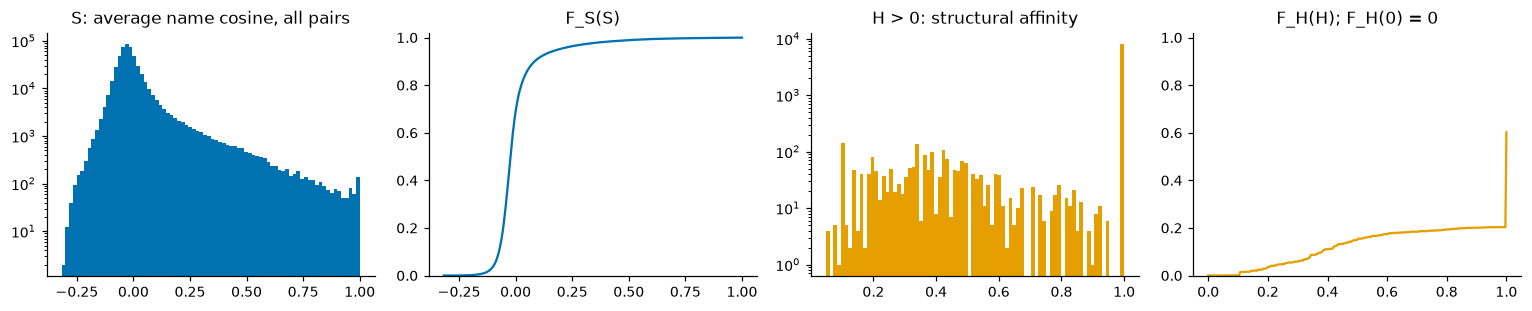

In [5]:
k2 = K - 1
n0 = len(items0)
cap2 = params.rho * n0 / cfg.budgets[k2]
P = csr_matrix(np.eye(n0))                              # level L2 starts from singletons
lvl = _Level(P @ Z0, np.ones(n0), P @ B0.toarray(), w0, params.alpha, cap2, params.gamma, None)
iu = np.triu_indices(n0, 1)
S_all, H_all = lvl._S()[iu], lvl._H()[iu]
print(f"level L{k2} of ≤{C0}: {n0} items → budget {cfg.budgets[k2]}; cap ρ·n/N = {params.rho}·{n0}/{cfg.budgets[k2]} "
      f"= {cap2:.2f} concept nodes")
print(f"item pairs: {len(S_all)}; pairs that share at least one clustering edge (H > 0): {(H_all > 0).sum()} "
      f"({(H_all > 0).mean():.2%})")
Hp = H_all[H_all > 0]
print(f"linked pairs with H = 1 exactly: {(Hp == 1).mean():.1%}  →  F_H(1) = {float(lvl.FH(np.array([1.0]))[0]):.3f}; "
      f"F_S(1) = {float(lvl.FS(np.array([1.0]))[0]):.3f}")
fig, ax = plt.subplots(1, 4, figsize=(14, 2.9))
ax[0].hist(S_all, bins=80, color="#0072B2"); ax[0].set_title("S: average name cosine, all pairs"); ax[0].set_yscale("log")
xs = np.linspace(S_all.min(), S_all.max(), 300)
ax[1].plot(xs, lvl.FS(xs), color="#0072B2"); ax[1].set_title("F_S(S)"); ax[1].set_ylim(0, 1.02)
ax[2].hist(Hp, bins=80, color="#E69F00"); ax[2].set_title("H > 0: structural affinity"); ax[2].set_yscale("log")
xh = np.linspace(0, 1, 300)
ax[3].plot(xh, lvl.FH(xh), color="#E69F00"); ax[3].set_title("F_H(H); F_H(0) = 0"); ax[3].set_ylim(0, 1.02)
fig.tight_layout()

The histograms show why the two signals need a common scale. S is defined for every pair (after centring, most pairs
sit near or below zero and a long tail reaches 1), while only a small share of pairs shares a clustering edge at all. The CDFs map both to ranks in [0, 1]. At the finest level
a large share of the linked pairs has H = 1 exactly. H is a weighted cosine of the two items' incidence rows, so
H = 1 means the two items touch exactly the same clustering edges; for singletons that is almost always one shared
edge.
A mid-rank CDF gives tied values their average rank, so these pairs, the strongest structural evidence there is, get
an F_H well below 1. The rank scale cuts the other way for names: because most name similarities sit near zero, even a
small positive S already has a high F_S. The consequence is worked out below the merge walk-through. The next cell finds
the pair the engine merges first and decomposes its score.

In [6]:
def pair_terms(lv, i, j):
    # S, H, F_S, F_H and the score of items i, j in the level's current state
    S = float(lv._S([i])[0, j]); H = float(lv._H([i])[0, j])
    FS, FH = float(lv.FS(np.array([S]))[0]), float(lv.FH(np.array([H]))[0])
    return S, H, FS, FH, params.alpha * FS + (1 - params.alpha) * FH


def members_of(group, items):
    return "; ".join(short(items[x], 32) for x in group[:4]) + (" …" if len(group) > 4 else "")


r = int(np.argmax(lvl.bval)); i, j = sorted((r, int(lvl.best[r])))
S, H, FS, FH, s = pair_terms(lvl, i, j)
assert abs(round(s, 9) - lvl.score[i, j]) < 1e-12
print(f"first merge: item {i} '{names[items0[i]]}'  +  item {j} '{names[items0[j]]}'")
print(f"  S = {S:.4f} → F_S = {FS:.4f};  H = {H:.4f} → F_H = {FH:.4f}")
print(f"  s = {params.alpha}·{FS:.4f} + {1 - params.alpha:.2f}·{FH:.4f} = {s:.6f}  (engine: {lvl.score[i, j]:.6f}); "
      f"size after merge 2 ≤ cap {cap2:.2f}")
top = np.lexsort((iu[1], iu[0], -lvl.score[iu]))[:8]     # the engine's order: score, then the lowest item index
pd.DataFrame([{"item A": a, "A": names[items0[a]][:40], "item B": b, "B": names[items0[b]][:40], **dict(zip(
    ["S", "H", "F_S", "F_H", "s"], pair_terms(lvl, a, b)))} for a, b in zip(iu[0][top], iu[1][top])]).round(6)

first merge: item 164 'RELAX1'  +  item 165 'RELAX2'
  S = 1.0000 → F_S = 1.0000;  H = 1.0000 → F_H = 0.6016
  s = 0.75·1.0000 + 0.25·0.6016 = 0.900393  (engine: 0.900393); size after merge 2 ≤ cap 8.48


,item A,A,item B,B,S,H,F_S,F_H,s
0,164,RELAX1,165,RELAX2,1.000,1.0,1.0,0.602,0.9
1,198,2-body descriptor,199,3-body descriptor,1.000,1.0,1.0,0.602,0.9
2,203,2b descriptor,204,3b descriptor,1.000,1.0,1.0,0.602,0.9
3,312,Scikit-learn,347,Scikit-learn,1.000,1.0,1.0,0.602,0.9
4,203,2b descriptor,205,MB descriptor,1.000,1.0,1.0,0.602,0.9
5,204,3b descriptor,205,MB descriptor,1.000,1.0,1.0,0.602,0.9
6,336,Hybrid functional HSE06,337,Hybrid functional PBE0,1.000,1.0,1.0,0.602,0.9
7,144,Automatminer Debug preset,146,Automatminer Heavy preset,0.999,1.0,1.0,0.602,0.9


The table lists the best-scoring pairs at the start of the level in the engine's order, so it shows why the winner
wins: pairs whose scores tie after rounding are ordered by the lowest item index, which is how the first merge is
chosen among them. The best candidates combine near-identical names (F_S ≈ 1) with identical edge sets (H = 1). Every pair in the table
has H = 1, so their order is decided by S and then by the item index. How much the structural term weighs against
names is worked out below the merge walk-through.

**What the merge changes.** `_Level.merge(i, j)` folds item j into item i and keeps everything the score needs, as
sums, so that no member has to be revisited:

- `sem[i] += sem[j]`: the summed name vectors (S is computed from the mean, sem / size);
- `size[i] += size[j]`: the number of concept nodes, which the cap checks;
- `C[i] += C[j]`: the endpoint counts per fine edge, i.e. how many of the super-node's members each edge contains;
- `X[i] = C[i] > 0` and `d[i] = X[i] · w`: the collapsed incidence, which records presence only, and the degree on it;
- then the row and column of i are rescored against every live item, and j is retired.

In [7]:
def cut(lv):
    lam = (lv.X[lv.alive] > 0).sum(axis=0)          # λ_e: live items each edge touches
    touched = lam > 0
    return connectivity_cut(lam[touched], lv.w[touched])


shared = (lvl.X[i] > 0) & (lvl.X[j] > 0)
multi1 = bool((shared & ((lvl.C[i] >= 2) | (lvl.C[j] >= 2))).any())
before = {"size": lvl.size[i], "edges touched (X>0)": int((lvl.X[i] > 0).sum()), "endpoint sum (ΣC)": lvl.C[i].sum(),
          "degree d": lvl.d[i], "connectivity cut": cut(lvl)}
num = float((lvl.X[i] * lvl.w) @ lvl.X[j])            # H's numerator: Σ w_e over the edges A and B share
lvl.merge(i, j)
after = {"size": lvl.size[i], "edges touched (X>0)": int((lvl.X[i] > 0).sum()), "endpoint sum (ΣC)": lvl.C[i].sum(),
         "degree d": lvl.d[i], "connectivity cut": cut(lvl)}
print(f"shared clustering edges: {int(shared.sum())}; H numerator Σ w_e = {num:.5f}; "
      f"drop of the connectivity cut Σ_e w_e(λ_e − 1) = {before['connectivity cut'] - after['connectivity cut']:.5f}")
assert abs((before["connectivity cut"] - after["connectivity cut"]) - num) < 1e-9   # Proposition 1 (report §4)
pd.DataFrame({"item i before": before, "item i after": after})

shared clustering edges: 1; H numerator Σ w_e = 0.04133; drop of the connectivity cut Σ_e w_e(λ_e − 1) = 0.04133


,item i before,item i after
size,1.000,2.000
edges touched (X>0),1.000,1.000
endpoint sum (ΣC),1.000,2.000
degree d,0.041,0.041
connectivity cut,38.965,38.923


The assertion is Proposition 1 of the report (§4): the numerator of H is exactly how much the merge reduces the
weighted connectivity cut Σ_e w_e (λ_e − 1), where λ_e is the number of super-nodes an edge touches. The structural
term therefore rewards merges that put a hyper-edge's endpoints together, for any arity, without expanding the edge
into pairs.

**The first merges of the level.** The engine is replayed for a few more steps with the same calls that `run` makes,
and every merged group is checked against the finished L2 partition in `out/≤2020/hierarchy.json`: greedy merges are
never undone, so each group must lie inside one final L2 super-node.

In [8]:
groups = {x: [x] for x in range(n0)}
groups[i] += groups.pop(j)
trace = [{"step": 1, "A": members_of([i], items0), "B": members_of([j], items0), "S": S, "H": H, "F_S": FS, "F_H": FH,
          "s": s, "linked": bool(shared.any()), "multi-endpoint": multi1}]
for step in range(2, 21):
    r = int(np.argmax(lvl.bval)); a, b = sorted((r, int(lvl.best[r])))
    Sa, Ha, FSa, FHa, sa = pair_terms(lvl, a, b)
    sh = (lvl.X[a] > 0) & (lvl.X[b] > 0)
    multi = bool((sh & ((lvl.C[a] >= 2) | (lvl.C[b] >= 2))).any())
    trace.append({"step": step, "A": members_of(groups[a], items0), "B": members_of(groups[b], items0), "S": Sa, "H": Ha,
                  "F_S": FSa, "F_H": FHa, "s": sa, "linked": bool(sh.any()), "multi-endpoint": multi})
    lvl.merge(a, b)
    groups[a] += groups.pop(b)

L2_of = {v: sid for sid, mem in concept_levels(C0)[k2].items() for v in mem}
for g in groups.values():
    assert len({L2_of[items0[x]] for x in g}) == 1, "a replayed merge contradicts out/"
print(f"after {len(trace)} merges: {lvl.alive.sum()} live items; every merged group lies in one L2 super-node of out/")
pd.DataFrame(trace).set_index("step").round(4)

after 20 merges: 998 live items; every merged group lies in one L2 super-node of out/


,A,B,S,H,F_S,F_H,s,linked,multi-endpoint
step,,,,,,,,,
1,RELAX1,RELAX2,1.000,1.0,1.0,0.602,0.9,True,False
2,2-body descriptor,3-body descriptor,1.000,1.0,1.0,0.602,0.9,True,False
3,2b descriptor,3b descriptor,1.000,1.0,1.0,0.602,0.9,True,False
4,Scikit-learn,Scikit‑learn,1.000,1.0,1.0,0.602,0.9,True,False
5,2b descriptor; 3b descriptor,MB descriptor,1.000,1.0,1.0,0.602,0.9,True,True
6,Hybrid functional HSE06,Hybrid functional PBE0,1.000,1.0,1.0,0.602,0.9,True,False
7,Automatminer Debug preset,Automatminer Heavy preset,0.999,1.0,1.0,0.602,0.9,True,False
8,FPMD simulations,PFF-MD simulations,0.999,1.0,1.0,0.602,0.9,True,False
9,LGPS solid electrolyte simulati…,LLZO solid electrolyte simulati…,0.999,1.0,1.0,0.602,0.9,True,False


**How much structure weighs against names at L2.** A pair that shares no edge (H = 0) can score at most α · 1 = α,
even with identical names. A pair with H = 1 scores α · F_S(S) + (1 − α) · F_H(1), so it beats every unlinked pair as
soon as F_S(S) > 1 − (1 − α) · F_H(1) / α. The cell computes this threshold on the level's own F_S, and the rank of
the first unlinked pair in the initial score order.

In [9]:
lv0 = _Level(P @ Z0, np.ones(n0), P @ B0.toarray(), w0, params.alpha, cap2, params.gamma, None)   # a fresh level
sc, S0, H0 = lv0.score[iu], lv0._S()[iu], lv0._H()[iu]
rank_s = np.empty(len(sc), int); rank_s[np.lexsort((iu[1], iu[0], -sc))] = np.arange(len(sc))
rank_S = np.empty(len(sc), int); rank_S[np.lexsort((iu[1], iu[0], -S0))] = np.arange(len(sc))
FH1 = float(lv0.FH(np.array([1.0]))[0])
need = 1 - (1 - params.alpha) * FH1 / params.alpha              # F_S a linked H = 1 pair needs to beat any unlinked pair
grid = np.unique(S0)
S_star = float(grid[np.searchsorted(lv0.FS(grid), need, side="right")])
first_unlinked = int(rank_s[H0 == 0].min())
above = rank_s < first_unlinked
print(f"F_H(1) = {FH1:.3f}: an H = 1 pair beats every unlinked pair once F_S(S) > {need:.3f}, i.e. S > {S_star:.3f} "
      f"(the {float(lv0.FS(np.array([S_star]))[0]):.0%} point of the name-similarity ranks)")
print(f"first pair without a shared edge in the initial score order: rank {first_unlinked}; all {above.sum()} pairs above "
      f"it share an edge, and their names reach down to S = {S0[above].min():.3f}")
print(f"merges of this level in out/ (run_info): {info['snapshots'][str(C0)]['levels'][k2]['merges']}, of which linked "
      f"{info['snapshots'][str(C0)]['levels'][k2]['linked']}")
low = np.where(above)[0][np.argsort(S0[above])[:6]]
pd.DataFrame([{"A": names[items0[iu[0][q]]][:38], "B": names[items0[iu[1][q]]][:38], "S": S0[q], "H": H0[q],
               "rank by S": rank_S[q], "rank by s": rank_s[q]} for q in low]).round(3)

F_H(1) = 0.602: an H = 1 pair beats every unlinked pair once F_S(S) > 0.799, i.e. S > 0.025 (the 80% point of the name-similarity ranks)
first pair without a shared edge in the initial score order: rank 3278; all 3278 pairs above it share an edge, and their names reach down to S = 0.025
merges of this level in out/ (run_info): 778, of which linked 682


,A,B,S,H,rank by S,rank by s
0,Automatminer Debug_single preset,Extensible featurizer sets,0.025,1.0,103790,3277
1,Data curation filtering,Pearson correlation-based feature redu,0.025,1.0,103688,3275
2,embedding layer,Cleaning stage,0.025,1.0,103677,3274
3,Kernel exponentiation,Dimer/trimer data inclusion,0.025,1.0,103668,3273
4,RMM-DIIS electronic minimizer,Plane-wave kinetic energy cut-off,0.025,1.0,103609,3272
5,Nosé-Hoover thermostat,Maximum bond variation check,0.025,1.0,103575,3270


So at the finest level the structural term is decisive for the order. Name similarity is concentrated near zero, so
its rank F_S is already high for weakly similar names, and the fixed structural bonus of an H = 1 pair then lifts it
above every pair that shares no edge, including pairs with identical names. The table shows the least name-similar of
these linked pairs: far down the order by S alone, they precede every unlinked pair. Names decide the order *among*
linked pairs; most merges of the level are linked (run_info), and unlinked, name-only merges come only once the linked
candidates are exhausted or blocked by the cap.

`linked` marks merges whose two items share at least one clustering edge. `multi-endpoint` marks merges where a
shared edge already has two or more endpoints on one side; there, scoring the edge by its endpoint counts (a clique
expansion) would differ from the presence-based H. `out/run_info.json` counts both kinds of merge for every level of
the run (§3).

## 3 · From one level to the next

Levels are built finest first: L2 from the concept nodes, then L1 from the L2 super-nodes, then L0 from the L1
super-nodes. Each coarser level is a new `_Level` whose items are the super-nodes just built, aggregated through the
membership matrix P: summed name vectors, sizes and summed endpoint counts. Merging only whole super-nodes is what
makes the levels nested (laminarity, P1), and stopping at exactly N_k items is the budget (P2). The cap ρ · n_t / N_k
grows as the budget shrinks. The mid-rank CDFs are refitted on each level's own item pairs.

The table reads the merge statistics that the build recorded for every level of every snapshot in
`out/run_info.json`:
- **merges**: merges performed;
- **linked**: merges whose two items shared a clustering edge;
- **multi-endpoint**: merges where native and clique-expansion scores would differ (§2);
- **prior**: merges where both items held stable old nodes, so that the temporal prior entered the score (§4);
- the cap, the largest super-node and the singletons.

In [10]:
rows = []
for c in CUTS:
    s = info["snapshots"][str(c)]
    for k, lv in enumerate(s["levels"]):
        rows.append({"snapshot": f"≤{c}", "level": f"L{k}", "items in": s["n_concept"] if k == K - 1 else s["levels"][k + 1]["super_nodes"],
                     "budget": lv["budget"], "cap": lv["cap"], "largest": lv["max_size"], "singletons": lv["singletons"],
                     "merges": lv["merges"], "linked": lv["linked"], "multi-endpoint": lv["multi_endpoint"], "prior": lv["prior"]})
lv_tab = pd.DataFrame(rows).set_index(["snapshot", "level"])
lv_tab.assign(**{"linked share": lv_tab["linked"] / lv_tab["merges"], "prior share": lv_tab["prior"] / lv_tab["merges"]})

items in  budget     cap  largest  singletons  merges  linked  \
snapshot level                                                                  
≤2020    L0           60      15  135.73      135           0      45      40   
         L1          240      60   33.93       32           1     180     121   
         L2         1018     240    8.48        8          16     778     682   
≤2022    L0           60      15  195.20      180           0      45      42   
         L1          240      60   48.80       48           0     180     123   
         L2         1464     240   12.20       12           5    1224     968   
≤2024    L0           60      15  377.20      354           0      45      44   
         L1          240      60   94.30       94           0     180     124   
         L2         2829     240   23.57       23           0    2589    2027   
≤2026    L0           60      15  530.67      476           0      45      45   
         L1          240      60  132.67      126           0     180     121   
         L2         3980     240   33.17       33           0    3740    2912   

                multi-endpoint  prior  linked share  prior share  
snapshot level                                                    
≤2020    L0                 39      0         0.889        0.000  
         L1                109      0         0.672        0.000  
         L2                361      0         0.877        0.000  
≤2022    L0                 42     45         0.933        1.000  
         L1                112    163         0.683        0.906  
         L2                528    653         0.791        0.533  
≤2024    L0                 43     45         0.978        1.000  
         L1                113    171         0.689        0.950  
         L2               1154    938         0.783        0.362  
≤2026    L0                 43     45         1.000        1.000  
         L1                111    178         0.672        0.989  
         L2               1671   2391         0.779        0.639

The aggregation is exact. Because super-nodes keep *summed* vectors and counts, S and H of two super-nodes equal the
values computed from all their members; only the rank scales F_S and F_H are refitted per level. The cell checks this
for two sibling L1 super-nodes of ≤2020: the dot product of the mean vectors equals the average pairwise name cosine
of their concept members, and the members' incidence rows added up equal the endpoint counts that
`coarse_hyperedges.json` records for these super-nodes at L1.

In [11]:
lv1 = concept_levels(C0)[1]
Bd = B0.toarray()
pres = {g: Bd[[pos0[v] for v in mem]].sum(axis=0) > 0 for g, mem in lv1.items()}
ids1 = sorted(lv1, key=lambda g: int(g.split(".")[1]))
a_id, b_id = max(((a, b) for a in ids1 for b in ids1 if a < b and sn[C0][a]["parent_id"] == sn[C0][b]["parent_id"]),
                 key=lambda ab: (int((pres[ab[0]] & pres[ab[1]]).sum()), ab))   # siblings sharing the most edges
A, Bm = [pos0[v] for v in sorted(lv1[a_id])], [pos0[v] for v in sorted(lv1[b_id])]
S_mean = float(Z0[A].mean(axis=0) @ Z0[Bm].mean(axis=0))
S_pair = float((Z0[A] @ Z0[Bm].T).mean())
print(f"two sibling L1 super-nodes of ≤{C0} (parent {sn[C0][a_id]['parent_id']}), the pair sharing the most edges:")
print(f"  {a_id} ({len(A)} concept nodes, '{sn[C0][a_id]['label']}') and {b_id} ({len(Bm)}, '{sn[C0][b_id]['label']}')")
print(f"  S from summed vectors {S_mean:.6f} = average pairwise cosine {S_pair:.6f}")
CA, CB = Bd[A].sum(axis=0), Bd[Bm].sum(axis=0)
XA, XB = CA > 0, CB > 0
num = float((XA * w0) @ XB); den = math.sqrt(float(XA @ w0) * float(XB @ w0))
print(f"  edges touched: {int(XA.sum())} and {int(XB.sum())}, shared {int((XA & XB).sum())}; "
      f"H = {num:.4f} / {den:.4f} = {num / den if den else 0:.4f}")
print(f"  largest endpoint count of a shared edge: {int(max(CA[XA & XB].max(initial=0), CB[XA & XB].max(initial=0)))} "
      "(H counts presence only; the counts are kept as metadata, §6)")
assert abs(S_mean - S_pair) < 1e-9
rec1 = coarse[C0]["1"]["edges"]
assert [r["fine_edge"] for r in rec1] == list(eids0)
for g, Cg in ((a_id, CA), (b_id, CB)):
    assert all(rec1[q]["endpoint_counts"].get(g, 0) == int(Cg[q]) for q in range(len(eids0)))
print("  summed endpoint counts equal the endpoint_counts of coarse_hyperedges.json at L1 for both super-nodes")

two sibling L1 super-nodes of ≤2020 (parent L0.1), the pair sharing the most edges:
  L1.34 (27 concept nodes, 'Gaussian approximation potentials') and L1.43 (23, 'Deep Potential Models')
  S from summed vectors 0.022265 = average pairwise cosine 0.022265
  edges touched: 29 and 24, shared 14; H = 0.2350 / 0.6099 = 0.3853
  largest endpoint count of a shared edge: 10 (H counts presence only; the counts are kept as metadata, §6)
  summed endpoint counts equal the endpoint_counts of coarse_hyperedges.json at L1 for both super-nodes


## 4 · The temporal prior

From the second snapshot on, each level also sees the previous snapshot. A concept node of ≤t−1 is **stable** at ≤t if
it is not a non-hub member of any clustering edge of a new paper, its hub status did not change, and no old edge it is
in gained or lost a hub (`tkh.hierarchy.stable_nodes`). For a pair of items that both hold stable nodes, the score becomes

  s_t(A, B) = (1 − γ) · s(A, B) + γ · Π(A, B),  γ = 0.5 here,

where Π(A, B) is the share of their stable member pairs that shared a level-k super-node at ≤t−1. A pair in which
either item holds no stable node keeps s. A new or touched node therefore starts without the prior; once it has been
merged with stable nodes, its super-node carries their counts and takes part in the prior from then on, at that level
and, through the aggregated counts, at the coarser levels. The cell recomputes the stable set of ≤2022 and checks it against `run_info.json`.
It then builds the start of level L2 of ≤2022 with the prior, exactly as `build_snapshot` does with the ≤2020
partition from `out/`.

In [12]:
snap1 = snapshot(tkh, C1)
hub1 = hubs(tkh, snap1, params.hub_frac)
stable1 = stable_nodes(tkh, snap0, snap1, set(hub0), hub1)
assert len(stable1) == info["snapshots"][str(C1)]["n_stable"]
items1 = concept_nodes(tkh, snap1)
new_nodes = set(items1) - set(items0)
print(f"≤{C1}: {len(items1)} concept nodes = {len(items0)} old + {len(new_nodes)} new; "
      f"stable {len(stable1)}, touched {len(items0) - len(stable1)}")

B1, w1, _, _ = incidence(tkh, snap1, items1, hub1, params.edge_weight)
Z1 = centred_lsa([names[v] for v in items1], params.lsa_dim)
prev_L2 = concept_levels(C0)[k2]
prev_of = {v: c for c, mem in prev_L2.items() for v in mem if v in stable1}
kidx = {c: q for q, c in enumerate(sorted(set(prev_of.values()), key=str))}
M = np.zeros((len(items1), len(kidx)))
for g, v in enumerate(items1):
    if v in prev_of:
        M[g, kidx[prev_of[v]]] = 1
n1 = len(items1)
cap1 = params.rho * n1 / cfg.budgets[k2]
lvl1 = _Level(Z1, np.ones(n1), B1.toarray(), w1, params.alpha, cap1, params.gamma, M)
p1 = {v: q for q, v in enumerate(items1)}

# one stable pair that shared an L2 super-node at ≤2020 and one that did not, both sharing an edge
H1 = lvl1._H()
st = sorted(stable1)
linked = lambda a, b: H1[p1[a], p1[b]] > 0   # noqa: E731
same = next((a, b) for a in st for b in st if a < b and prev_of[a] == prev_of[b] and linked(a, b))
diff = next((a, b) for a in st for b in st if a < b and prev_of[a] != prev_of[b] and linked(a, b))
# a stable node never shares an edge with a new node (any edge of a new paper touches its members), so the third
# example pair is the most name-similar stable/new pair
S1 = lvl1._S()
ia_, ib_ = [p1[v] for v in st], [p1[v] for v in sorted(new_nodes)]
q = np.unravel_index(np.argmax(S1[np.ix_(ia_, ib_)]), (len(ia_), len(ib_)))
newp = (st[q[0]], sorted(new_nodes)[q[1]])
assert not linked(*newp)
rows = []
for kind, (a, b) in [("stable, same L2 at ≤2020", same), ("stable, different L2 at ≤2020", diff), ("stable + new node", newp)]:
    ia, ib = sorted((p1[a], p1[b]))
    S_, H_ = float(lvl1._S([ia])[0, ib]), float(lvl1._H([ia])[0, ib])
    s_plain = params.alpha * float(lvl1.FS(np.array([S_]))[0]) + (1 - params.alpha) * float(lvl1.FH(np.array([H_]))[0])
    Pi = float(lvl1._Pi([ia])[0, ib])
    s_t = (1 - params.gamma) * s_plain + params.gamma * Pi if not math.isnan(Pi) else s_plain
    assert abs(round(s_t, 9) + 1e-10 * s_plain - lvl1.score[ia, ib]) < 1e-8
    rows.append({"pair": kind, "A": short(a, 30), "B": short(b, 30), "s": s_plain, "Π": Pi, "s_t (engine)": lvl1.score[ia, ib]})
pd.DataFrame(rows).round(4)

≤2022: 1464 concept nodes = 1018 old + 446 new; stable 876, touched 142


,pair,A,B,s,Π,s_t (engine)
0,"stable, same L2 at ≤2020",Output layer,Pooling layer,0.906,1.0,0.953
1,"stable, different L2 at ≤2020",Output layer,Crystal graph representation,0.276,0.0,0.138
2,stable + new node,Matbench,Matbench,0.750,NaN,0.750


Π is 1 for a stable pair that the previous snapshot grouped together and 0 for a stable pair it kept apart; a pair
with a new node has no Π (NaN) and keeps its plain score. At L2 the items start as singletons, so Π is exactly 0 or 1:
with γ = 0.5 a previously grouped stable pair scores (s + 1)/2 ≥ 0.5 and a previously separated one s/2 ≤ 0.5. Among
stable pairs the previous grouping therefore decides the order, whatever names and structure say; intermediate
values of Π arise only after merges and at the coarser levels. Such a pair never shares a clustering edge either: an edge
of a new paper touches all its members, so none of them is stable. New nodes can therefore join old groups only
through names or through other new or touched nodes. 

## 5 · What a super-node preserves

The engine keeps, for every live item, exactly what the score needs. The output keeps what a reader or an agent needs.

| kept during the build (`_Level`) | in the output (`hierarchy.json`) |
|---|---|
| summed name vectors `sem`, size | `member_ids`: every member, concept and anchored |
| endpoint counts per fine edge `C`, presence `X`, degree `d` | coarse hyper-edges with endpoint counts (`coarse_hyperedges.json`, §6) |
| stable-member counts per previous super-node `M` | persistent `id` and the events log (`temporal_events.json`) |
| — | `level`, `parent_id`, `label`, `gloss` |

What the output does not keep: the merge order, the scores, and which fine members of a super-node took part in a
coarse edge (only fine edge ids and counts). The next cell shows one exported record.

In [13]:
rec = next(s for s in hier[CL]["supernodes"] if s["level"] == 1)
mem_types = Counter(ntype[v] for v in rec["member_ids"])
print(json.dumps({**rec, "member_ids": f"[{len(rec['member_ids'])} ids]"}, indent=1, ensure_ascii=False))
pd.DataFrame({"members": mem_types}).assign(role=lambda d: ["concept" if t in CONCEPT_TYPES else "anchored" for t in d.index]) \
    .sort_values(["role", "members"], ascending=[False, False])

{
 "id": "L1.1",
 "level": 1,
 "parent_id": "L0.1",
 "member_ids": "[181 ids]",
 "label": "Graph Neural Networks",
 "gloss": "Models for materials exploration and property prediction."
}


,members,role
method,29,concept
component,22,concept
task,21,concept
metric,19,concept
technique,11,concept
problem,6,concept
dataset,4,concept
cited_work,24,anchored
claim,22,anchored
future_topic,12,anchored


**Anchored members.** Every non-concept node joins the super-node of one concept node, its *anchor*
(`tkh.hierarchy.anchors`):
- a claim joins the method of its claims edge (or else the method its paper presents);
- an article joins the method it presents;
- any other node (author, cited work, future-work topic) joins the method presented by the earliest paper it occurs in.

Anchoring makes every level a partition of the whole snapshot, and lets a drill-down reach the papers and claims
behind a group, while these nodes never influence how concept nodes are grouped. The cell recomputes the anchors of
the last snapshot and checks, at every level, that each anchored node sits in its anchor's super-node.

In [14]:
snapL = snapshot(tkh, CL)
conceptL = set(concept_nodes(tkh, snapL))
anc = anchors(tkh, snapL, conceptL)
where = [{v: s["id"] for s in hier[CL]["supernodes"] if s["level"] == k for v in s["member_ids"]} for k in range(K)]
assert all(where[k][v] == where[k][a] for k in range(K) for v, a in anc.items())
print(f"≤{CL}: {len(conceptL)} concept nodes, {len(anc)} anchored nodes; every anchored node is in its anchor's "
      f"super-node at all {K} levels")
ex = []
for t in ("claim", "article", "cited_work", "author", "future_topic"):
    v = next((x for x in sorted(anc) if ntype[x] == t), None)
    if v is not None:
        ex.append({"type": t, "node": short(v, 55), "anchor (method)": short(anc[v], 40), "L0 super-node": where[0][v]})
pd.DataFrame(ex)

≤2026: 3980 concept nodes, 1818 anchored nodes; every anchored node is in its anchor's super-node at all 3 levels


,type,node,anchor (method),L0 super-node
0,claim,The modified convolution function reduces the mean abs…,crystal graph convolutional neural netw…,L0.1
1,article,Neural Message Passing for Quantum Chemistry,Message Passing Neural Network,L0.1
2,cited_work,ConvLSTM,ConvLSTM-based fracture prediction model,L0.10
3,author,Yuzhi Zhang,DeePMD-kit v2,L0.16
4,future_topic,Application of CGCNN to additional material classes be…,crystal graph convolutional neural netw…,L0.1


**Parents and identities.** A super-node's `parent_id` is the coarser super-node that contains all its members; the
cell checks laminarity directly on the files. Identities persist across snapshots: `tkh/temporal.py` matches every
super-node to its largest-overlap predecessor at the same level and logs one fate per super-node and transition: a
persisting super-node *continues* (same members), *grows* (a superset) or *changes* (other members); otherwise it is
a *merge*, a *split* or a *birth*. Deaths cannot occur: every member of an old super-node is still in the next
snapshot, and every level partitions the whole snapshot, so every old super-node overlaps some new one.

In [15]:
for c in CUTS:
    for s in hier[c]["supernodes"]:
        if s["level"] > 0:
            assert set(s["member_ids"]) <= set(sn[c][s["parent_id"]]["member_ids"]), (c, s["id"])
print("laminar: every super-node's members lie inside its parent, at every level of every snapshot")
ev = pd.DataFrame(events)
ev["transition"] = [f"first snapshot ≤{b}" if pd.isna(a) else f"{int(a)}→{b}" for a, b in zip(ev["from_snapshot"], ev["to_snapshot"])]
ev.pivot_table(index=["transition", "level"], columns="event", values="to_ids", aggfunc="size", fill_value=0)

laminar: every super-node's members lie inside its parent, at every level of every snapshot


event                       birth  change  continue  growth  merge  split
transition           level                                               
2020→2022            0          1       5         1       7      1      0
                     1          3       8        16      25      4      2
                     2         15       8       142      56     15      2
2022→2024            0          1       9         0       1      2      1
                     1          2      22         6      22      4      2
                     2         22      25        82      87     20      2
2024→2026            0          0      11         1       3      0      0
                     1          2      22         3      22      5      3
                     2          5      45        98      81      7      2
first snapshot ≤2020 0         15       0         0       0      0      0
                     1         60       0         0       0      0      0
                     2        240       0         0       0      0      0

## 6 · The hyper-edge coarsening decision

At every level, each fine clustering edge e has to be given a form over the super-nodes (task T4). Let n_e be its
arity after hub removal, c_S(e) the number of its endpoints in super-node S, λ_e = #{S : c_S(e) > 0} the number of
super-nodes it touches, and m_e = max_S c_S(e). `tkh.coarsen.collapse` assigns exactly one class:

| condition | class | what the coarse level keeps |
|---|---|---|
| m_e = n_e (λ_e = 1) | **internal** | no coarse edge; the weight still counts in the super-node's degree d_A |
| 1 < m_e < n_e (2 ≤ λ_e < n_e) | **partial** | one coarse hyper-edge over the λ_e super-nodes, endpoint counts as metadata |
| m_e = 1 (λ_e = n_e) | **uncollapsed** | the fine edge itself, one endpoint per super-node |

An edge with λ_e ≥ 3 is also flagged **multi-way**: it stays one hyper-edge and is never split into pairs. The
decision is not a separate step after the build: the engine's incidence `X` is this collapsed incidence (presence),
and `coarse_hyperedges.json` writes it out for every level. The cell recomputes `collapse` from the partitions in
`out/` and checks it against the file for every edge and level of the last snapshot.

In [16]:
hubL = hubs(tkh, snapL, params.hub_frac)
assert sorted(hubL) == info["snapshots"][str(CL)]["hubs"]
itemsL = concept_nodes(tkh, snapL)
BL, wL, eidsL, relsL = incidence(tkh, snapL, itemsL, hubL, params.edge_weight)
posL = {v: q for q, v in enumerate(itemsL)}
levL = concept_levels(CL)
coll = {}
for k in range(K):
    recs = coarse[CL][str(k)]["edges"]
    assert [r["fine_edge"] for r in recs] == list(eidsL)
    ids = sorted(levL[k])
    lab = np.empty(len(itemsL), int)
    for q, g in enumerate(ids):
        lab[[posL[v] for v in levL[k][g]]] = q
    coll[k] = collapse(lab, BL)
    assert list(coll[k]["lam"]) == [r["lambda"] for r in recs] and list(coll[k]["cls"]) == [r["class"] for r in recs]
print(f"≤{CL}: collapse() on the out/ partitions reproduces coarse_hyperedges.json for all {len(eidsL)} edges at "
      f"all {K} levels")

summ = []
for k in range(K):
    cls, lam = coll[k]["cls"], coll[k]["lam"]
    summ.append({"level": f"L{k}", **{c: int((cls == c).sum()) for c in ("internal", "partial", "uncollapsed")},
                 "multi-way (λ ≥ 3)": int(coll[k]["multiway"].sum()),
                 "internal weight share": float(wL[cls == "internal"].sum() / wL.sum()),
                 "connectivity cut Σ w(λ−1)": connectivity_cut(lam, wL)})
summ.append({"level": "fine (singletons)", "internal": 0, "partial": 0, "uncollapsed": len(eidsL),
             "multi-way (λ ≥ 3)": int((np.asarray(BL.sum(axis=0)).ravel() >= 3).sum()), "internal weight share": 0.0,
             "connectivity cut Σ w(λ−1)": connectivity_cut(np.asarray(BL.sum(axis=0)).ravel(), wL)})
pd.DataFrame(summ).set_index("level")

≤2026: collapse() on the out/ partitions reproduces coarse_hyperedges.json for all 554 edges at all 3 levels


,internal,partial,uncollapsed,multi-way (λ ≥ 3),internal weight share,connectivity cut Σ w(λ−1)
level,,,,,,
L0,71,355,128,312,0.131,11.001
L1,35,348,171,381,0.068,14.460
L2,22,338,194,416,0.037,17.939
fine (singletons),0,0,554,517,0.000,50.628


Reading the table from the finest row upwards: every fine edge starts uncollapsed, and coarsening moves edges to
partial and finally internal as their endpoints are merged. The connectivity cut, the quantity whose reduction the
structural term rewards (Proposition 1), falls accordingly. Multi-way edges remain at every level, because an edge
can span many super-nodes even at L0. One edge followed through the three levels:

In [17]:
ar = np.asarray(BL.sum(axis=0)).ravel()
cls_path = lambda j: tuple(coll[k]["cls"][j] for k in range(K))   # noqa: E731
want = [("internal", "partial", "uncollapsed"), ("partial", "partial", "uncollapsed"), ("internal", "partial", "partial")]
j_e = next(j for w_ in want for j in np.argsort(-ar) if cls_path(j) == w_ and 4 <= ar[j] <= 12)
eid = eidsL[j_e]
row = snapL.edges.loc[eid]
mem = [v for v in dict.fromkeys(row["members"]) if v in posL]
print(f"fine edge {eid}: {row['relation_type']}, paper {row['article_id']} ({row['article_year']}), "
      f"n_e = {int(ar[j_e])} concept members, weight {wL[j_e]:.5f}")
for v in mem:
    if v in hubL:
        print(f"  {ntype[v]:<10} {short(v, 45):<47} hub (removed from the clustering edge)")
        continue
    print(f"  {ntype[v]:<10} {short(v, 45):<47} " + "  ".join(f"L{k}: {[g for g, m in levL[k].items() if v in m][0]}"
                                                               for k in range(K)))
rows = []
for k in range(K):
    r = coarse[CL][str(k)]["edges"][j_e]
    cnt = r["endpoint_counts"]
    rows.append({"level": f"L{k}", "λ_e": r["lambda"], "m_e": max(cnt.values()), "class": r["class"], "multi-way": r["multiway"],
                 "endpoint counts": ", ".join(f"{g}: {c}" for g, c in cnt.items()),
                 "pairs credited in H": r["lambda"] * (r["lambda"] - 1) // 2})
pd.DataFrame(rows).set_index("level")

fine edge h_00106: addresses, paper 5396 (2018), n_e = 5 concept members, weight 0.04225
  method     crystal graph convolutional neural networks     L0: L0.1  L1: L1.1  L2: L2.18
  task       Continuous property regression                  L0: L0.13  L1: L1.67  L2: L2.164
  task       Binary classification                           L0: L0.13  L1: L1.67  L2: L2.169
  task       Per‑atom energy extraction                      L0: L0.1  L1: L1.1  L2: L2.118
  task       Materials design rule discovery                 L0: L0.13  L1: L1.17  L2: L2.243
  task       materials science                               hub (removed from the clustering edge)


,λ_e,m_e,class,multi-way,endpoint counts,pairs credited in H
level,,,,,,
L0,2,3,partial,False,"L0.1: 2, L0.13: 3",1
L1,3,2,partial,True,"L1.1: 2, L1.17: 1, L1.67: 2",3
L2,5,1,uncollapsed,True,"L2.118: 1, L2.164: 1, L2.169: 1, L2.18: 1, L2.243: 1",10


At each level the edge contributes its weight w_e once to the H numerator of every pair of super-nodes it touches,
λ_e(λ_e − 1)/2 pairs, whatever the endpoint counts are. A super-node holding several of the edge's endpoints gets no
more credit than one holding a single endpoint. That is the design choice of §4 of the report: a clique expansion
would pay a super-node more the more of one paper's star it already holds, and so reward bundling single papers.
The endpoint counts are kept in the record (metadata), but not in the score.

## 7 · Labels and glosses from the input data

Levels L0 and L1 are labelled (`tkh.label.LABELLED_LEVELS`); the finest level L2 is not, so an agent reaches its
super-nodes through their labelled parents and their member names. For every labelled super-node, `tkh/label.py`:

1. **collects evidence lines** from its snapshot (`Evidence.items`): member concepts ("name [type]" with aliases),
   *facts*, member claims, future-work topics and paper titles. A fact is a clustering edge with at least one *tail*
   member in the group, written as "head relation in-group tails" (up to eight tails, the head named even when it lies
   outside the group, benchmark results added for `evaluated_on`). Cited works are excluded, because citations are the
   coherence ruler, and authors carry no meaning.
2. **splits them 50/50** (`split_evidence`), seeded by the members and stratified by kind: per kind, the seen half
   gets the larger half. Each half is then ranked and capped at `max_items` lines. Node lines are ranked by how many
   snapshot papers mention the node, and facts by how many group members they name. The labeller sees only the *seen*
   half; the *held-out* half is reserved for the faithfulness judge (report §5.1; Appendix A.4, label faithfulness).
3. **adds contrast:** the concept names of the same-level groups that share the most clustering edges with this one,
   which the label must not fit.
4. **renders the prompt** (`configs/prompts/labeller.txt`) and asks the labeller model for JSON
   `{"label", "gloss"}`; the answer is cleaned (`clean_output`) and written to `hierarchy.json`. The exact input is
   recorded in `label_inputs.json` with the prompt's hash.

The cells replay all four steps for the largest L0 super-node and its largest L1 child (in concept nodes) at the
last snapshot, check
each against `out/`, and then replay every labelled super-node.
The LLM answer comes from the cache; nothing is sent to a model.

In [18]:
labeller = LLMLabeller(tkh, cfg)                 # offline: CachedLLM raises on a cache miss
ev = labeller.ev


def replay(c, sid):
    s = sn[c][sid]
    mem = s["member_ids"]
    items = ev.items(c, mem)
    seen, held = split_evidence(items, mem, labeller.s["seed"], labeller.s["max_items"])
    rec = label_inputs[c][sid]
    assert seen == rec["seen"] and held == rec["held_out"], "evidence split differs from label_inputs.json"
    prompt = labeller.prompt(c, seen, mem)
    assert hashlib.sha256(prompt.encode()).hexdigest() == rec["prompt_sha256"], "prompt differs from the recorded one"
    resp = labeller.llm.complete(prompt)
    assert clean_output(resp) == (s["label"], s["gloss"]), "cached answer differs from hierarchy.json"
    return items, seen, held, prompt, resp


for k in LABELLED_LEVELS:                        # contrast needs every group of the level, as in the build
    labeller.set_context(CL, [s["member_ids"] for s in hier[CL]["supernodes"] if s["level"] == k])
nconc = lambda s: sum(map(is_concept, s["member_ids"]))   # noqa: E731  size in concept nodes, as everywhere else
ex0 = max((s for s in hier[CL]["supernodes"] if s["level"] == 0), key=nconc)["id"]
ex1 = max((s for s in hier[CL]["supernodes"] if s["parent_id"] == ex0), key=nconc)["id"]
replay(CL, ex0)
print(f"{ex0} (L0): label '{sn[CL][ex0]['label']}' reproduced from its evidence, prompt and cached answer")
items, seen, held, prompt, resp = replay(CL, ex1)
print(f"{ex1} (L1, child of {ex0}), {nconc(sn[CL][ex1])} concept nodes, {len(sn[CL][ex1]['member_ids'])} members:")
kind_of = {x: k for k, x, _ in items}
seen_all, held_all = split_evidence(items, sn[CL][ex1]["member_ids"], labeller.s["seed"], cap=10**9)   # the split before the cap
kinds = pd.DataFrame({"evidence lines": Counter(t for t, _, _ in items),
                      "seen half, before cap": Counter(kind_of[t] for t in seen_all),
                      "held-out half, before cap": Counter(kind_of[t] for t in held_all),
                      f"seen, cap {labeller.s['max_items']} (labeller)": Counter(kind_of[t] for t in seen),
                      f"held out, cap {labeller.s['max_items']} (judge)": Counter(kind_of[t] for t in held)}).fillna(0).astype(int)
kinds

L0.2 (L0): label 'Graph Neural Networks' reproduced from its evidence, prompt and cached answer
L1.23 (L1, child of L0.2), 118 concept nodes, 193 members:


,evidence lines,"seen half, before cap","held-out half, before cap","seen, cap 40 (labeller)","held out, cap 40 (judge)"
paper,2,1,1,0,0
claim,34,17,17,0,0
concept,118,58,59,28,28
future,9,5,4,0,0
fact,37,19,18,12,12


The split is stratified by kind, so before the cap both halves hold about half of every kind. The cap then keeps
each half's most widely mentioned lines: concepts are ranked by the number of snapshot papers that mention them and
facts by how many group members they name, while a claim or a title usually comes from a single paper. For a large
super-node the labeller therefore sees concepts and facts and, typically, none of its claims or titles. The prompt the labeller received, rebuilt from the recorded seen
half (its hash equals the one in `label_inputs.json`):

In [19]:
lines = prompt.splitlines()
ev_start = next(q for q, l in enumerate(lines) if l.startswith("- "))
ev_end = next(q for q in range(ev_start, len(lines)) if not lines[q].startswith("- "))
print("\n".join(lines[:ev_start + 8]))
print(f"  … ({ev_end - ev_start} evidence lines in total) …")
print("\n".join(lines[ev_end:]))
print("\nraw cached answer:", json.dumps(resp, ensure_ascii=False))
print("hierarchy.json:   ", json.dumps({"label": sn[CL][ex1]["label"], "gloss": sn[CL][ex1]["gloss"]}, ensure_ascii=False))

You name groups of concepts extracted from scientific papers on machine learning for materials science and chemistry (literature up to 2026).

Below is evidence about ONE group, one item per line: member concepts ("name [type]"), statements from the papers' knowledge graph about these members (relations, benchmark results, claims, future work) and titles of the papers they come from. It is a sample of the evidence.

- Integrable Deep Neural Network (IDNN) for learning high-dimensional free-energy density and chemical potential functions extends DFT+U, Semi-Grand Canonical Monte Carlo, Cahn-Hilliard equation, Allen-Cahn equation, Umbrella sampling, Billiard Walk, deal.II library, classical nucleation theory
- Integrable Deep Neural Network (IDNN) for learning high-dimensional free-energy density and chemical potential functions uses component Active learning workflow for sampling free-energy derivative data, Monte Carlo sampling with bias potentials, Active learning workflow with Billia

The same replay for every labelled super-node of every snapshot: evidence split, prompt hash and cached answer each
have to reproduce `out/`.

In [20]:
n_ok = 0
for c in CUTS:
    for k in LABELLED_LEVELS:
        labeller.set_context(c, [s["member_ids"] for s in hier[c]["supernodes"] if s["level"] == k])
    for s in hier[c]["supernodes"]:
        if s["level"] in LABELLED_LEVELS:
            replay(c, s["id"])
            n_ok += 1
print(f"{n_ok} labelled super-nodes: evidence split, prompt and cached answer reproduce out/ for every one "
      f"(cache hits {labeller.llm.hits}, live calls {labeller.llm.calls})")
assert labeller.llm.calls == 0
pd.DataFrame([{"id": s["id"], "concept members": sum(map(is_concept, s["member_ids"])), "label": s["label"], "gloss": s["gloss"]}
              for s in hier[CL]["supernodes"] if s["level"] == 0]).set_index("id")

300 labelled super-nodes: evidence split, prompt and cached answer reproduce out/ for every one (cache hits 302, live calls 0)


,concept members,label,gloss
id,,,
L0.1,473,Equivariant Graph Neural Networks,Models using E(3) equivariance for materials simulations
L0.10,53,Fracture prediction models,Models for predicting crack patterns and fracture toughness in crystalline solids.
L0.11,365,Graph Neural Networks,Models for crystal structure and property prediction.
L0.12,221,MLIP generalization frameworks,Techniques for evaluating and improving machine learning interatomic potentials.
L0.13,409,Graph Neural Networks for Materials,Models for material property prediction and structure analysis.
L0.14,80,Equivariant Graph Attention,Techniques and components for equivariant graph attention in materials modeling.
L0.16,454,Diffusion Coefficient Prediction,Models for predicting ionic and lithium diffusion in materials.
L0.17,104,Graph Neural Networks,Models for materials property prediction using graph structures.
L0.18,61,Graph-based neural networks,Models using graph neural networks for material property prediction.


## 8 · The resulting hierarchies across all levels

**Icicles.** One panel per snapshot, one row per level (L0 on top). Each box is a super-node, as wide as its number of
concept nodes and placed under its parent; the colour is its most common concept type, and the shading is that type's
share. The larger L0 boxes carry their (truncated) labels.

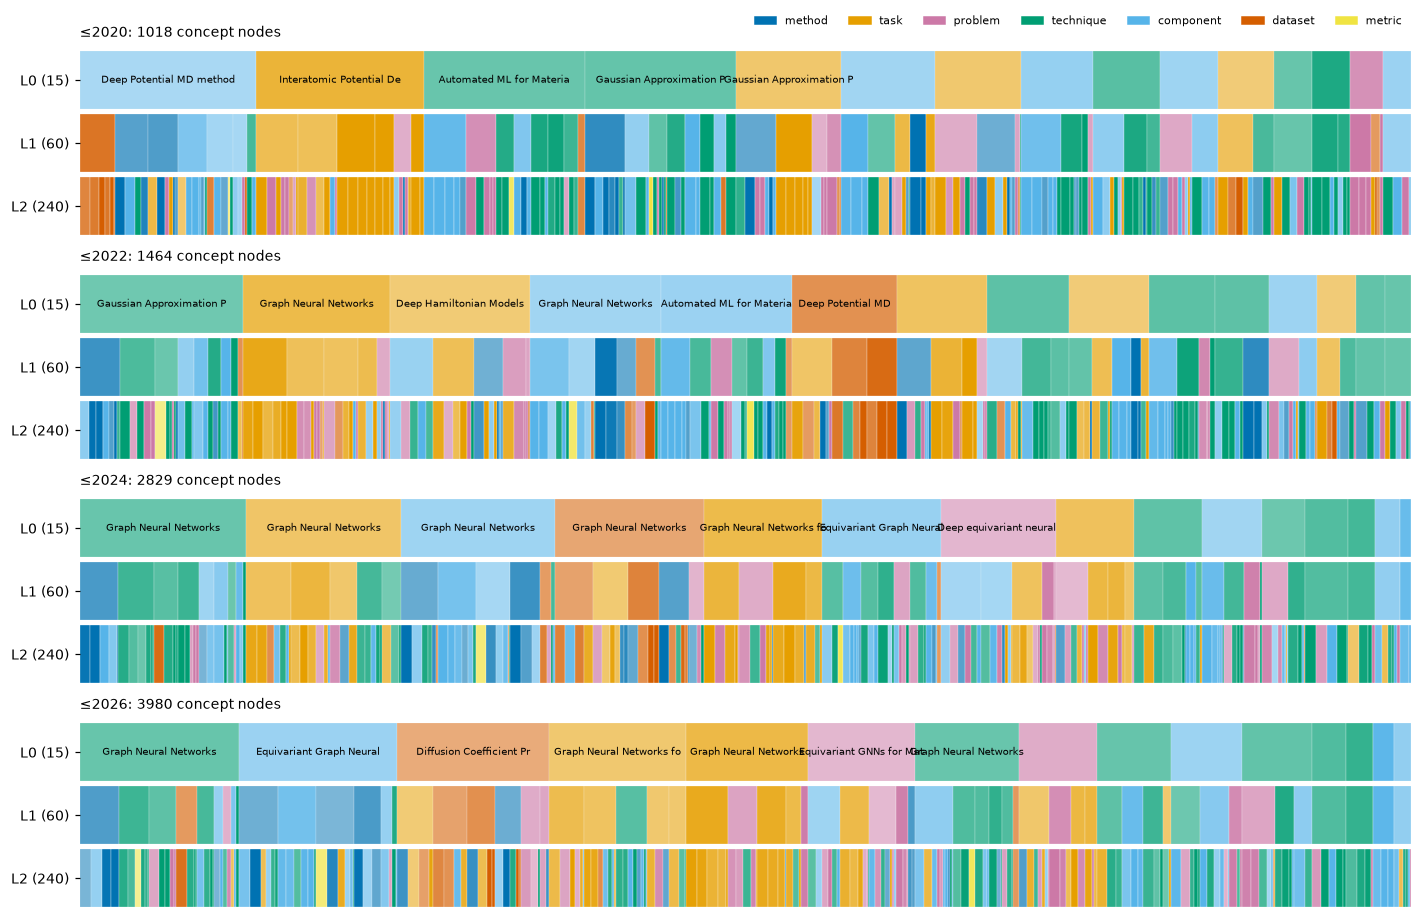

In [21]:
TYPE_COL = dict(zip(CONCEPT_TYPES, ["#0072B2", "#E69F00", "#CC79A7", "#009E73", "#56B4E9", "#D55E00", "#F0E442"]))


def order(c):
    # super-nodes per level in drawing order: larger first, children under their parent
    kids = {}
    for s in hier[c]["supernodes"]:
        kids.setdefault(s["parent_id"], []).append(s["id"])
    size = {i: sum(map(is_concept, s["member_ids"])) for i, s in sn[c].items()}
    out = [[] for _ in range(K)]

    def walk(i, k):
        out[k].append(i)
        for ch in sorted(kids.get(i, []), key=lambda x: -size[x]):
            walk(ch, k + 1)
    for r in sorted(kids[None], key=lambda x: -size[x]):
        walk(r, 0)
    return out, size


fig, axes = plt.subplots(len(CUTS), 1, figsize=(13, 2.1 * len(CUTS)))
for ax, c in zip(axes, CUTS):
    lv, size = order(c)
    total = sum(size[i] for i in lv[0])
    for k in range(K):
        x = 0
        for i in lv[k]:
            t = Counter(ntype[v] for v in sn[c][i]["member_ids"] if is_concept(v))
            top, cnt = t.most_common(1)[0]
            ax.add_patch(plt.Rectangle((x, K - 1 - k), size[i], 0.92, color=TYPE_COL[top], alpha=0.35 + 0.65 * cnt / size[i],
                                       lw=0.2, ec="white"))
            if k == 0 and size[i] / total > 0.075:
                ax.text(x + size[i] / 2, K - 1 + 0.46, sn[c][i]["label"][:24], ha="center", va="center", fontsize=6.5)
            x += size[i]
    ax.set_xlim(0, total); ax.set_ylim(0, K)
    ax.set_yticks([K - 1 - k + 0.46 for k in range(K)], [f"L{k} ({len(lv[k])})" for k in range(K)])
    ax.set_xticks([]); ax.set_title(f"≤{c}: {total} concept nodes", loc="left", fontsize=9)
    for sp in ax.spines.values():
        sp.set_visible(False)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col) for col in TYPE_COL.values()], labels=list(TYPE_COL),
               ncol=7, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.05), fontsize=7)
fig.tight_layout()

**Sizes and composition.** Super-node sizes per level at the last snapshot against the cap ρ · n_t / N_k, and the
concept-type mix of each L0 super-node.

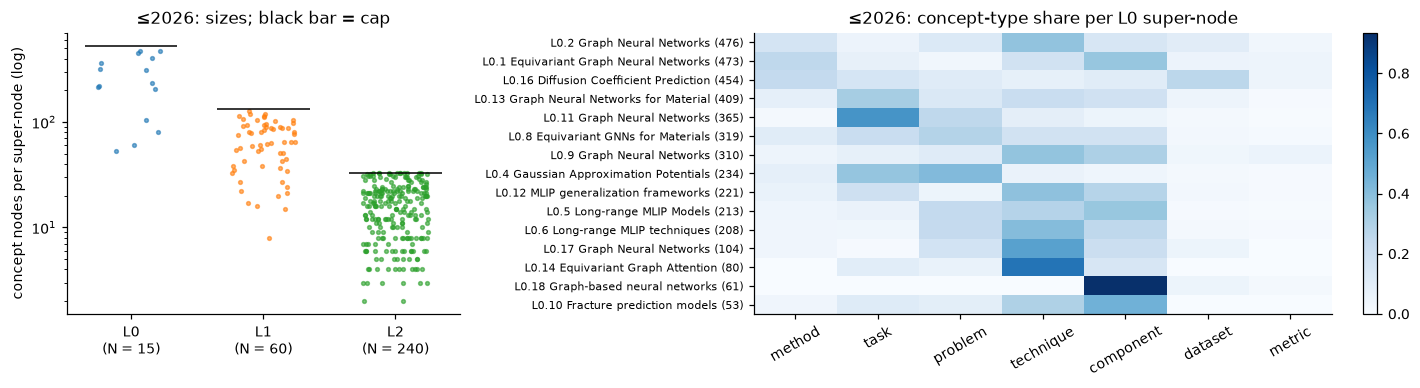

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), width_ratios=[1, 1.6])
for k in range(K):
    sz = [len(m) for m in levL[k].values()]
    ax[0].scatter(np.full(len(sz), k) + np.random.default_rng(k).uniform(-0.25, 0.25, len(sz)), sz, s=6, alpha=0.6)
    ax[0].hlines(info["snapshots"][str(CL)]["levels"][k]["cap"], k - 0.35, k + 0.35, color="black", lw=1)
ax[0].set_yscale("log"); ax[0].set_xticks(range(K), [f"L{k}\n(N = {cfg.budgets[k]})" for k in range(K)])
ax[0].set_ylabel("concept nodes per super-node (log)"); ax[0].set_title(f"≤{CL}: sizes; black bar = cap")
l0 = sorted(levL[0], key=lambda g: -len(levL[0][g]))
mix = pd.DataFrame([Counter(ntype[v] for v in levL[0][g]) for g in l0], index=l0).reindex(columns=CONCEPT_TYPES).fillna(0)
share = mix.div(mix.sum(axis=1), axis=0)
im = ax[1].imshow(share.values, aspect="auto", cmap="Blues", vmin=0, vmax=share.values.max())
ax[1].set_xticks(range(len(CONCEPT_TYPES)), CONCEPT_TYPES, rotation=30)
ax[1].set_yticks(range(len(l0)), [f"{g} {sn[CL][g]['label'][:34]} ({len(levL[0][g])})" for g in l0], fontsize=7)
ax[1].set_title(f"≤{CL}: concept-type share per L0 super-node"); fig.colorbar(im, ax=ax[1], fraction=0.03)
fig.tight_layout()

**One branch, drilled down.** The largest L0 super-node of the last snapshot with its L1 children (labels) and, under
each child, its largest L2 grandchildren with their most widely mentioned members.

In [23]:
papersL = {v: len(p) for v, p in node_papers(tkh, snapL).items()}
kids = {}
for s in hier[CL]["supernodes"]:
    kids.setdefault(s["parent_id"], []).append(s["id"])
csize = lambda i: sum(map(is_concept, sn[CL][i]["member_ids"]))   # noqa: E731
print(f"{ex0}  {sn[CL][ex0]['label']}  ({csize(ex0)} concept nodes, {len(kids[ex0])} L1 children)")
for ch in sorted(kids[ex0], key=lambda x: -csize(x)):
    print(f"├─ {ch:<7} {sn[CL][ch]['label'][:60]:<62} {csize(ch):>4}  ({len(kids.get(ch, []))} L2)")
    for g in sorted(kids.get(ch, []), key=lambda x: -csize(x))[:3]:
        top = sorted((v for v in sn[CL][g]["member_ids"] if is_concept(v)), key=lambda v: (-papersL.get(v, 0), surface[v]))[:3]
        print(f"│    └─ {g:<8} {csize(g):>3}: " + "; ".join(short(v, 28) for v in top))

L0.2  Graph Neural Networks  (476 concept nodes, 9 L1 children)
├─ L1.23   Graph Neural Networks                                           118  (4 L2)
│    └─ L2.113    33: Alexandria; Alexandria dataset; CUDA graphs
│    └─ L2.97     33: 2DIRECT sampling; AIMD sampling; Ab-initio molecular dynamic…
│    └─ L2.52     29: NequIP; Allegro; GGA+U
├─ L1.36   Crystal Graph Networks                                           89  (6 L2)
│    └─ L2.226    25: Adaptive mesh refinement wi…; Automatic error detection a…; Bi-directional virtual node…
│    └─ L2.148    22: Be (local scaling); C (local scaling); Dataset size scaling charac…
│    └─ L2.116    18: Batch‑wise out‑of‑distribut…; Bayesian optimization with …; Box‑plot of hull‑distance e…
├─ L1.51   Migration barrier prediction                                     81  (5 L2)
│    └─ L2.156    31: DFT-NEB calculations; DFT-NEB convergence acceler…; Debye temperature estimation
│    └─ L2.212    17: Methfessel-Paxton smearing; Nernst‑Einstein

**The coarse hypergraph at L0.** What the top level keeps of the structure: for every pair of L0 super-nodes, the
total weight of the coarse edges that touch both (the H numerator at L0), and on the diagonal the weight of the edges
that became internal to the super-node.

total edge weight 6.00: internal to an L0 super-node 0.78, in coarse edges 5.22; summed over L0 pairs 20.72 (an edge over λ super-nodes counts in λ(λ−1)/2 pairs, as in H)


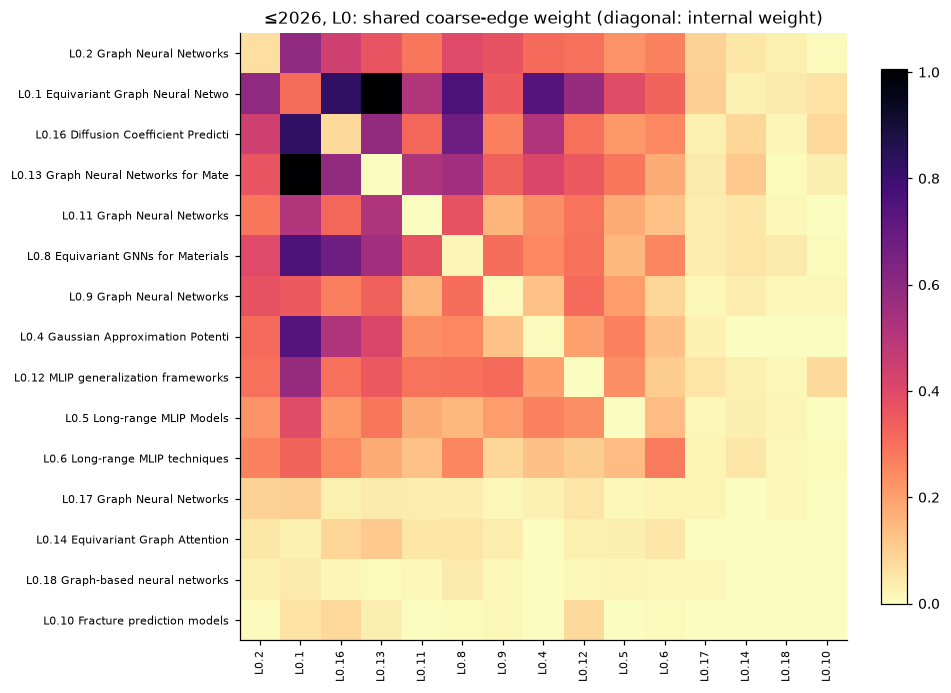

In [24]:
recs0 = coarse[CL]["0"]["edges"]
W = pd.DataFrame(0.0, index=l0, columns=l0)
for r in recs0:
    g = list(r["endpoint_counts"])
    if r["class"] == "internal":
        W.loc[g[0], g[0]] += r["weight"]
    for a in g:
        for b in g:
            if a != b:
                W.loc[a, b] += r["weight"]
fig, ax = plt.subplots(figsize=(8, 6.4))
im = ax.imshow(W.values, cmap="magma_r")
ax.set_xticks(range(len(l0)), l0, rotation=90, fontsize=7)
ax.set_yticks(range(len(l0)), [f"{g} {sn[CL][g]['label'][:30]}" for g in l0], fontsize=7)
ax.set_title(f"≤{CL}, L0: shared coarse-edge weight (diagonal: internal weight)")
fig.colorbar(im, ax=ax, fraction=0.04); fig.tight_layout()
off = W.values[~np.eye(len(l0), dtype=bool)].sum() / 2
print(f"total edge weight {wL.sum():.2f}: internal to an L0 super-node {np.trace(W.values):.2f}, in coarse edges "
      f"{wL.sum() - np.trace(W.values):.2f}; summed over L0 pairs {off:.2f} (an edge over λ super-nodes counts in "
      "λ(λ−1)/2 pairs, as in H)")

**Lineage of the top level.** Concept-node size of every persistent L0 id per snapshot and its label at the last
snapshot. Ids persist through the largest-overlap matching of §5: a row that starts later is a birth or the new
child of a split, and a row that ends early is an id whose super-node merged into another one.

,≤2020,≤2022,≤2024,≤2026,label at ≤2026
L0.1,135.0,144.0,326.0,473.0,Equivariant Graph Neural Networks
L0.2,116.0,180.0,354.0,476.0,Graph Neural Networks
L0.3,29.0,60.0,NaN,NaN,—
L0.4,80.0,98.0,165.0,234.0,Gaussian Approximation Potentials
L0.5,55.0,72.0,127.0,213.0,Long-range MLIP Models
L0.6,44.0,52.0,92.0,208.0,Long-range MLIP techniques
L0.7,43.0,43.0,NaN,NaN,—
L0.8,66.0,154.0,245.0,319.0,Equivariant GNNs for Materials
L0.9,123.0,144.0,251.0,310.0,Graph Neural Networks
L0.10,29.0,29.0,53.0,53.0,Fracture prediction models


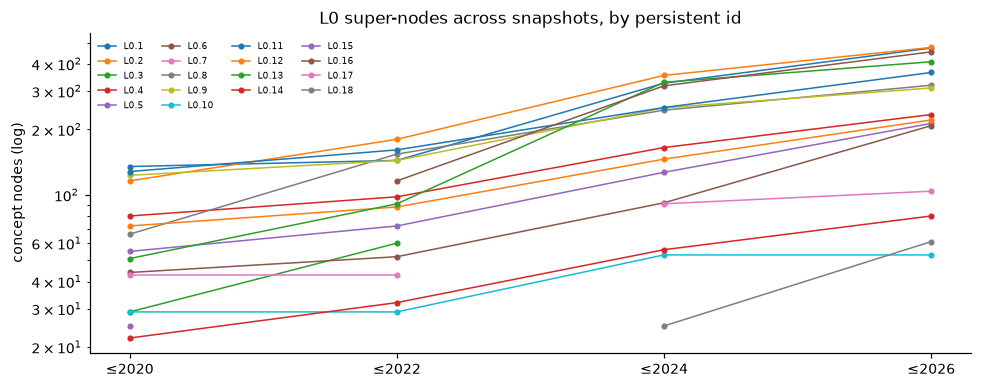

In [25]:
lin = pd.DataFrame({f"≤{c}": {g: len(m) for g, m in concept_levels(c)[0].items()} for c in CUTS})
lin["label at ≤%d" % CL] = [sn[CL][g]["label"] if g in sn[CL] else "—" for g in lin.index]
lin = lin.loc[sorted(lin.index, key=lambda g: int(g.split(".")[1]))]
fig, ax = plt.subplots(figsize=(9, 3.6))
for g, r in lin.iterrows():
    ax.plot(range(len(CUTS)), [r[f"≤{c}"] for c in CUTS], marker="o", ms=3, lw=1, label=g)
ax.set_xticks(range(len(CUTS)), [f"≤{c}" for c in CUTS]); ax.set_yscale("log"); ax.set_ylabel("concept nodes (log)")
ax.set_title("L0 super-nodes across snapshots, by persistent id"); ax.legend(ncol=4, fontsize=6, frameon=False)
fig.tight_layout()
lin

## 9 · Summary

Every statement below is read from a cell above; the asserts of §§1–7 hold on the files in `out/`.

- **A merge** is the global argmax of s = α·F_S + (1 − α)·F_H over the feasible pairs, with ties going to the lowest
  item index (§2). The first merges of the finest level join near-identical names (spelling variants, numbered presets, paired
  descriptors) that also share their clustering edge. Despite α = 0.75, structure decides the order at L2: name
  similarity is concentrated near zero, so its rank is high even for weakly similar names, and the bonus of a pair
  with identical edge sets lifts it above every pair that shares no edge, identical names included. Names then
  order the linked pairs, and name-only merges come last.
- **The merge state is sufficient and exact.** A super-node carries summed name vectors, its size, and endpoint
  counts per fine edge, so S and H of two super-nodes equal the values computed from all their members (§3). H's
  numerator equals the drop in the connectivity cut (Proposition 1, §2).
- **Levels and the prior.** Each level re-runs the engine on the super-nodes of the finer one, with its own cap and
  rank scales (§3). From the second snapshot on, the temporal prior enters most coarse merges (`run_info` prior
  share, §3). At L2 it ranks previously grouped stable pairs ahead of previously separated ones, whatever names and structure
  say. A new node starts without it, and cannot share an edge with a stable node; it enters the prior only once its
  super-node also holds stable nodes (§4).
- **The output record** keeps members (concept and anchored), parent, persistent id, label and gloss. Anchored nodes
  always sit with their anchor, the levels are laminar, and identities follow the largest-overlap matching (§5).
- **Hyper-edge coarsening** is decided per edge and level by λ_e and m_e. Coarsening moves edges from uncollapsed to
  partial to internal, and the connectivity cut falls level by level, but even at L0 most edge weight stays in coarse
  edges between super-nodes, and multi-way edges remain at every level (§6). The top level is therefore not a set of
  structural communities: most of the structure lies between its groups and stays explicit in the coarse edges.
- **Labels** are reproducible from the inputs. For every labelled super-node, the evidence split, the prompt and the
  cached answer reproduce `out/` (§7). The cap keeps mostly concepts and facts in the labeller's view. Several L0
  labels repeat a broad theme ("Graph Neural Networks") despite the contrast groups, their glosses overlap, and the
  repetition continues among L1 children (§§7–8). A label alone often does not distinguish a super-node from its
  neighbours; the member names do.
- **The hierarchies** (§8) stay within their caps at every level. The largest L0 super-nodes approach the cap at the
  last snapshot, and the type mix varies between L0 groups. The top level is stable in identity: most L0 ids persist
  and grow across snapshots, with a few births, merges and splits.